# GeoVision/GeoGuesser

**CSE 5717 · Country classification from street-view images**

In this notebook, I completed the initial exploration and baseline experiments for our GeoVision project.

I started by loading and analyzing the GeoGuessr dataset, examining the distribution of country labels, and visualizing sample street-view images. I then created a balanced subset of 900 images across nine countries and used a pretrained ResNet50 model to extract 2,048 image features per image.

After splitting the dataset into 70% training, 15% validation, and 15% testing, I trained and compared two classification models: Logistic Regression and Support Vector Machine (SVM).

Logistic Regression performed better, achieving 37.0% validation accuracy compared to SVM's 31.1%, and reached 34.1% accuracy on the held-out test set.

I also generated performance comparisons, classification reports, a confusion matrix, and sample predictions to better understand where the model performed well and which countries were commonly confused. Although the initial results show room for improvement, both models performed better than the 11.1% random-guessing baseline.

Moving forward, the next steps are to increase the number of training images per country, experiment with hyperparameter tuning, explore additional classification models, and potentially fine-tune the pretrained CNN to improve overall prediction accuracy.

---

# Imports:

In [16]:
import pandas as pd
import requests
import numpy as np
from PIL import Image
from datasets import load_dataset, Image as HFImage
import base64
from io import BytesIO
from PIL import Image
from IPython.display import HTML
import torch
from torchvision import models

# Example Instance

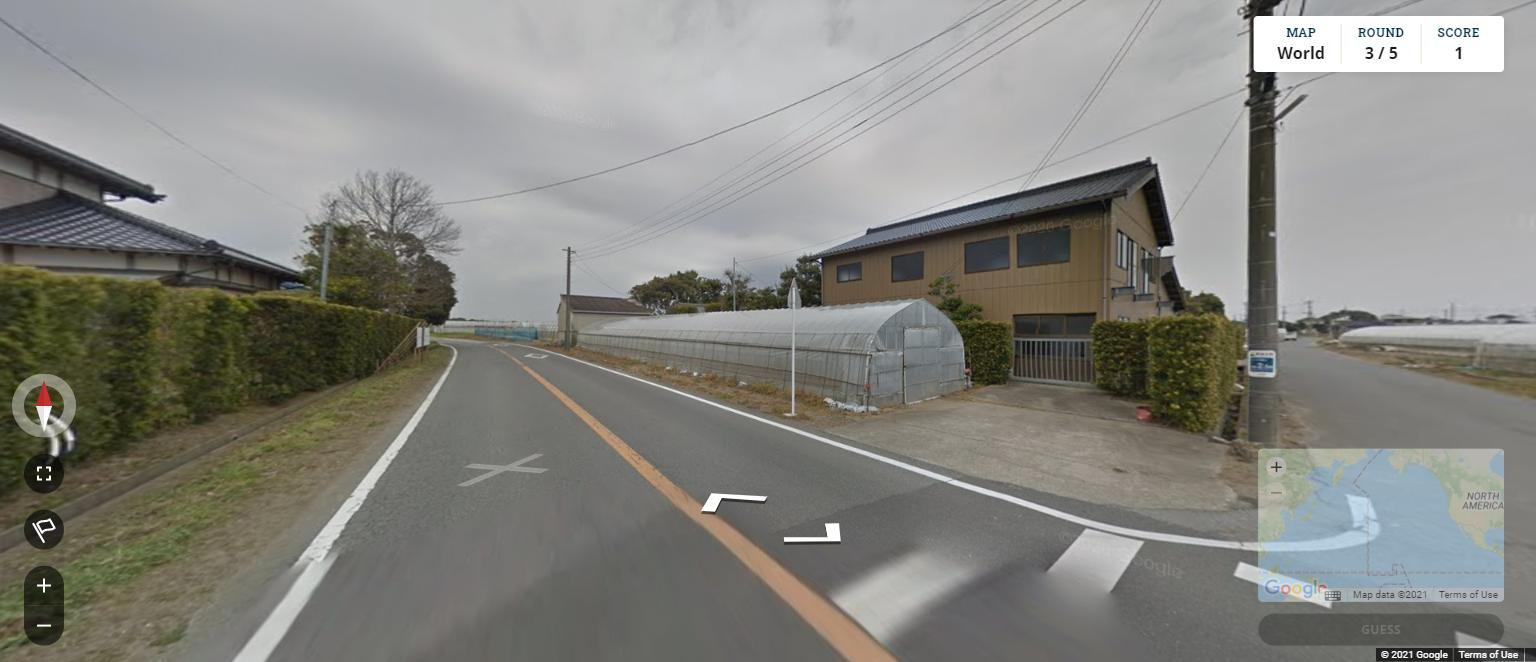

Country: Japan


In [17]:
ds = load_dataset("moondream/geoguessr-countries-finetune", split="train")
ds = ds.cast_column("image", HFImage(decode=True))

sample = ds[0]
display(sample["image"])
print("Country:", sample["country"])

,image,country
0,,Japan
1,,South Africa
2,,Australia
3,,Chile
4,,Australia

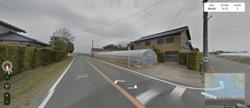
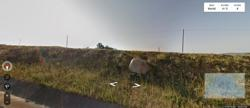
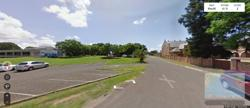
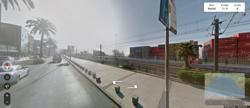
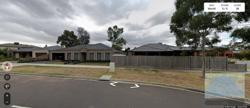

In [18]:
def head(ds, n=5, width=250):
    df = ds.select(range(n)).to_pandas()

    def to_img_tag(img):
        im = Image.open(BytesIO(img["bytes"]))
        im.thumbnail((width, width))
        buf = BytesIO()
        im.save(buf, format="JPEG")
        b64 = base64.b64encode(buf.getvalue()).decode()
        return f'<img src="data:image/jpeg;base64,{b64}" width="{width}">'

    df["image"] = df["image"].apply(to_img_tag)
    return HTML(df.to_html(escape=False))

head(ds)

In [19]:
# Count labels without decoding every full-resolution image into a pandas dataframe.
pd.Series(ds["country"], name="country").value_counts()

,count
country,
Japan,2673
France,2487
United Kingdom,1723
Brazil,1613
Russia,1225
Australia,1187
Canada,963
South Africa,821
Spain,748


# Methods
1. Run the images through a pretrained CNN or CLIP once to get embeddings
2. Train your logistic regression, SVM, and gradient boosting models on those embeddings.
3. Fine-tune the CNN itself as a fourth, “deep learning” model to compare against.

In [20]:
from io import BytesIO
from PIL import Image

def get_img(sample):
    img = sample["image"]
    if isinstance(img, dict):          # decode=False → raw bytes
        img = Image.open(BytesIO(img["bytes"]))
    return img.convert("RGB")

In [21]:
weights = models.ResNet50_Weights.DEFAULT
cnn = models.resnet50(weights=weights) # embedding models
cnn.fc = torch.nn.Identity()          # drop classifier → outputs 2048-dim features
cnn.eval()
preprocess = weights.transforms()

@torch.no_grad()
def cnn_embed(samples):
    batch = torch.stack([preprocess(get_img(s)) for s in samples])
    return cnn(batch).numpy()

X = cnn_embed([ds[i] for i in range(10)])
print(X.shape)   # (10, 2048)

(10, 2048)


Next Meeting
1. Determine Embedding model
2. Assign models
   1. 2 models each
3. Fine tune final model/ test model (ensemble?)

---
# GeoVision: Baseline Experiments for Team Meeting

**Goal:** Train and compare two simple country classifiers using the ResNet50 image embeddings already demonstrated above.

**What is already done:** Dataset exploration, country counts, sample image visualization, a pretrained ResNet50 feature extractor, and an 8-image embedding test that produced an `(8, 2048)` array.

**New experiment:** Balanced 9-country subset → ResNet50 embeddings → stratified train/validation/test split → Logistic Regression and SVM → classification metrics and visualization.

**Important:** All results in the next cells are **computed when you run them**. There are no prefilled accuracy numbers. The notebook deliberately uses a smaller subset as a first baseline that can be expanded later.

**Environment:** Run the original cells above first, including the cell that creates `ds`, `cnn`, `preprocess`, and `get_img`. If needed, install requirements in your selected VS Code Jupyter kernel: `pip install scikit-learn matplotlib joblib`.


## 1. Select Countries

In [22]:
counts = pd.Series(ds["country"], name="country").value_counts()[:10]
counts.head(10).index.tolist()

['Japan',
 'France',
 'United Kingdom',
 'Brazil',
 'Russia',
 'Australia',
 'Canada',
 'South Africa',
 'Spain',
 'Finland']

Selected 14168 street-view images
Japan             2673
France            2487
United Kingdom    1723
Brazil            1613
Russia            1225
Australia         1187
Canada             963
South Africa       821
Spain              748
Finland            728


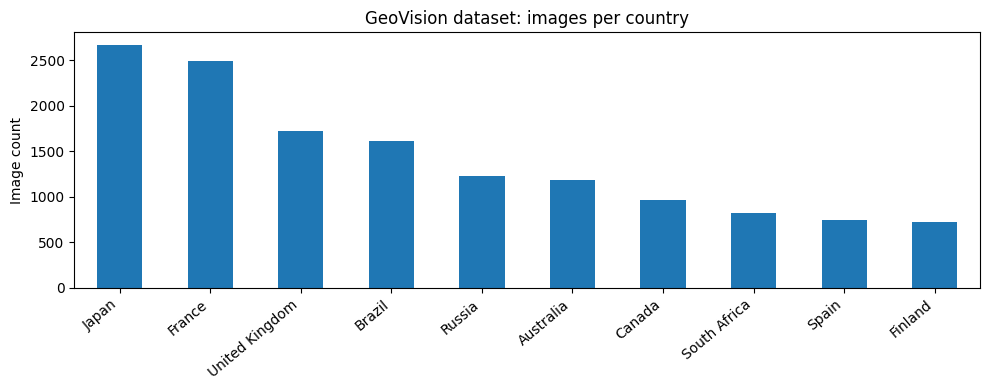

In [23]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import joblib

SEED = 42
COUNTRIES = counts.head(10).index.tolist()
SAMPLES_PER_COUNTRY = counts.head(10).min()


df = pd.DataFrame({"country": ds["country"]})
selected_indices = df.index[df["country"].isin(COUNTRIES)].to_numpy()
y_country = df.loc[selected_indices, "country"].to_numpy()

print(f"Selected {len(selected_indices)} street-view images")
print(pd.Series(y_country).value_counts().reindex(COUNTRIES).to_string())

plt.figure(figsize=(10, 4))
pd.Series(y_country).value_counts().reindex(COUNTRIES).plot(kind="bar")
plt.title("GeoVision dataset: images per country")
plt.ylabel("Image count")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

## 2. Extract image embeddings in batches

Use the **same pretrained ResNet50** created earlier in the notebook

In [24]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
BATCH_SIZE = 32  # lower to 8 if you run out of memory
cnn = cnn.to(DEVICE).eval()
print("Embedding device:", DEVICE)

@torch.inference_mode()
def embed_dataset_rows(row_indices, batch_size=BATCH_SIZE):
    vectors = []
    for start in range(0, len(row_indices), batch_size):
        batch_rows = row_indices[start:start + batch_size]
        batch = torch.stack([preprocess(get_img(ds[int(i)])) for i in batch_rows]).to(DEVICE)
        vectors.append(cnn(batch).cpu().numpy())
        if (start // batch_size) % 20 == 0:
            print(f"Embedded {min(start + batch_size, len(row_indices))}/{len(row_indices)}")
    return np.concatenate(vectors)

X_features = embed_dataset_rows(selected_indices)
print("Feature array shape:", X_features.shape)   # (7200, 2048)

Embedding device: cuda
Embedded 32/14168
Embedded 672/14168
Embedded 1312/14168
Embedded 1952/14168
Embedded 2592/14168
Embedded 3232/14168
Embedded 3872/14168
Embedded 4512/14168
Embedded 5152/14168
Embedded 5792/14168
Embedded 6432/14168
Embedded 7072/14168
Embedded 7712/14168
Embedded 8352/14168
Embedded 8992/14168
Embedded 9632/14168
Embedded 10272/14168
Embedded 10912/14168
Embedded 11552/14168
Embedded 12192/14168
Embedded 12832/14168
Embedded 13472/14168
Embedded 14112/14168
Feature array shape: (14168, 2048)


## 3. Stratified train / validation / test split

70% training, 15% validation, 15% held-out test. Split **before fitting classifiers**, and never fit the scaler on validation/test data. The validation set chooses which model to use; the final test set is evaluated only after the selection.

Because this dataset has country labels but no location IDs in the selected columns, nearby street-view images could potentially occur in different splits. This is a limitation to document in the final report.

In [25]:
row_positions = np.arange(len(selected_indices))
train_pos, remainder_pos = train_test_split(
    row_positions, test_size=0.30, random_state=SEED, stratify=y_country
)
val_pos, test_pos = train_test_split(
    remainder_pos, test_size=0.50, random_state=SEED,
    stratify=y_country[remainder_pos]
)

X_train, y_train = X_features[train_pos], y_country[train_pos]
X_val, y_val = X_features[val_pos], y_country[val_pos]
X_test, y_test = X_features[test_pos], y_country[test_pos]

print(f"Training: {len(y_train)} images")
print(f"Validation: {len(y_val)} images")
print(f"Test (held out): {len(y_test)} images")
print(f"Number of classes: {len(np.unique(y_train))}")
print(f"Uniform random-guessing accuracy: {100/len(COUNTRIES):.1f}%")

Training: 9917 images
Validation: 2125 images
Test (held out): 2126 images
Number of classes: 10
Uniform random-guessing accuracy: 10.0%


## 4. Train two classifiers: Logistic Regression and SVM

Both models see the **same 2,048-dimensional ResNet50 embeddings**, and both have independent `StandardScaler` steps fit exclusively on the training data. This makes the initial comparison fair.

- Logistic Regression: interpretable linear baseline.
- SVM (RBF): nonlinear classifier that can capture relationships beyond a simple linear boundary.

Only validation metrics are displayed here, not test results.

Training: Logistic Regression
Training: SVM (RBF)

Validation comparison:
              Model  Validation Accuracy  Validation Macro F1
          SVM (RBF)                0.572                0.527
Logistic Regression                0.544                0.514


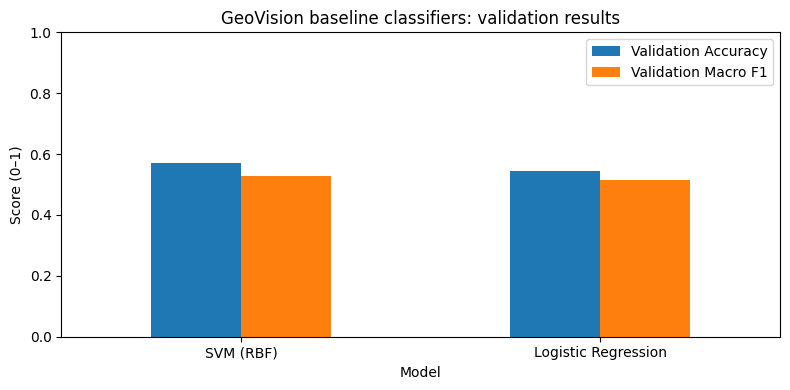

In [26]:
classifiers = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0, gamma="scale"))
    ])
}

validation_rows = []
for model_name, clf in classifiers.items():
    print("Training:", model_name)
    clf.fit(X_train, y_train)
    val_pred = clf.predict(X_val)
    validation_rows.append({
        "Model": model_name,
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation Macro F1": f1_score(y_val, val_pred, average="macro")
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "Validation Macro F1", ascending=False
).reset_index(drop=True)

print("\nValidation comparison:")
print(validation_results.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
# validation_results.to_csv(RESULTS_DIR / "validation_comparison.csv", index=False)

ax = validation_results.set_index("Model")[[
    "Validation Accuracy", "Validation Macro F1"
]].plot(kind="bar", ylim=(0, 1), figsize=(8, 4), rot=0)
ax.set_title("GeoVision baseline classifiers: validation results")
ax.set_ylabel("Score (0–1)")
ax.legend(loc="upper right")
plt.tight_layout()
# plt.savefig(RESULTS_DIR / "validation_model_comparison.png", dpi=160)
plt.show()

## 5. Evaluate the validation winner once on the held-out test set

Choose by **validation macro F1**, not test accuracy. Report overall test accuracy, macro F1, per-country precision/recall/F1 and the confusion matrix. The test results are meaningful only after these cells have run. Keep both models saved for discussion.

Selected model (highest validation macro F1): SVM (RBF)
Held-out TEST accuracy: 0.564 (56.4%)
Held-out TEST macro F1: 0.519

Per-country classification report:
                precision    recall  f1-score   support

         Japan       0.59      0.86      0.70       401
        France       0.47      0.65      0.55       373
United Kingdom       0.60      0.45      0.52       259
        Brazil       0.61      0.69      0.64       242
        Russia       0.51      0.40      0.45       184
     Australia       0.58      0.40      0.47       178
        Canada       0.56      0.37      0.45       145
  South Africa       0.71      0.45      0.55       123
         Spain       0.62      0.19      0.29       112
       Finland       0.73      0.50      0.59       109

      accuracy                           0.56      2126
     macro avg       0.60      0.50      0.52      2126
  weighted avg       0.58      0.56      0.55      2126



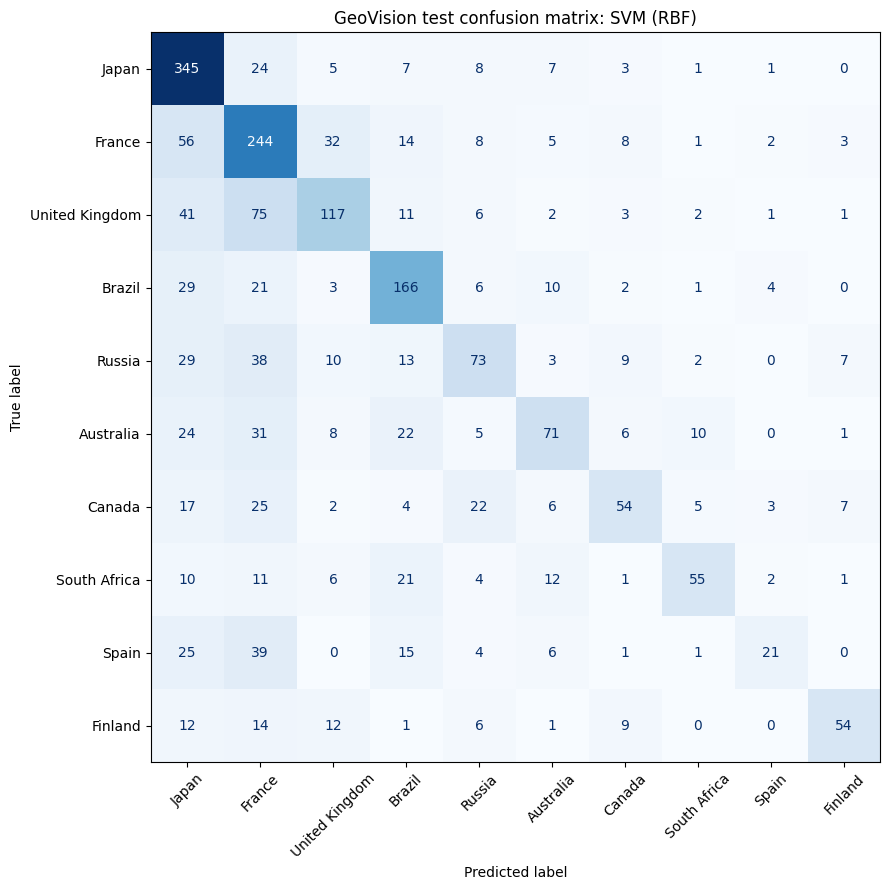

In [27]:
best_name = validation_results.loc[0, "Model"]
best_classifier = classifiers[best_name]
test_pred = best_classifier.predict(X_test)

accuracy = accuracy_score(y_test, test_pred)
macro_f1 = f1_score(y_test, test_pred, average="macro")
print("Selected model (highest validation macro F1):", best_name)
print(f"Held-out TEST accuracy: {accuracy:.3f} ({accuracy * 100:.1f}%)")
print(f"Held-out TEST macro F1: {macro_f1:.3f}")
print("\nPer-country classification report:")
print(classification_report(y_test, test_pred, labels=COUNTRIES, zero_division=0))

report = classification_report(
    y_test, test_pred, labels=COUNTRIES,
    zero_division=0, output_dict=True
)
# pd.DataFrame(report).transpose().to_csv(RESULTS_DIR / "test_classification_report.csv")

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=COUNTRIES, xticks_rotation=45,
    cmap="Blues", ax=ax, colorbar=False
)
ax.set_title(f"GeoVision test confusion matrix: {best_name}")
plt.tight_layout()
# plt.savefig(RESULTS_DIR / "test_confusion_matrix.png", dpi=180)
plt.show()

for model_name, clf in classifiers.items():
    safe_name = "logistic_regression" if model_name == "Logistic Regression" else "svm_rbf"
    # joblib.dump(clf, RESULTS_DIR / f"{safe_name}.joblib")

# with (RESULTS_DIR / "run_summary.json").open("w") as fh:
#     json.dump({
#         "embedding_model": "torchvision ResNet50 DEFAULT weights (2048-dimensional)",
#         "countries": COUNTRIES,
#         "samples_per_country": SAMPLES_PER_COUNTRY,
#         "train_count": len(train_pos),
#         "validation_count": len(val_pos),
#         "test_count": len(test_pos),
#         "selected_model": best_name,
#         "test_accuracy": accuracy,
#         "test_macro_f1": macro_f1,
#         "seed": SEED
#     }, fh, indent=2)
# print("Saved metrics, confusion matrix, and both classifiers in", RESULTS_DIR)

## 6. Qualitative demo: example predictions

After running the evaluation, show a few street-view images with their **actual** and **predicted** countries. These sample outputs are useful to discuss what the classifier can and cannot recognize.

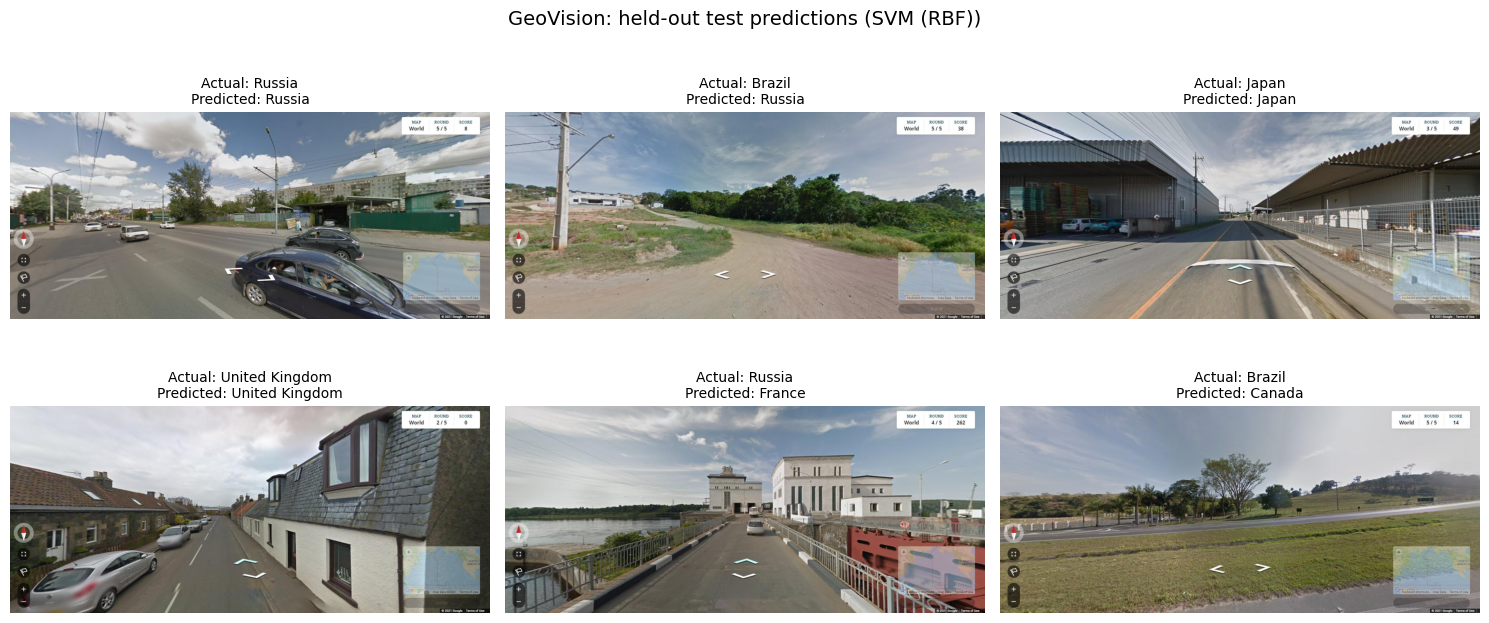

In [28]:
demo_rng = np.random.default_rng(SEED)
demo_positions = demo_rng.choice(len(test_pos), size=min(6, len(test_pos)), replace=False)
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, demo_i in zip(axs.flat, demo_positions):
    row_in_original_ds = int(selected_indices[test_pos[demo_i]])
    sample_img = get_img(ds[row_in_original_ds])
    ax.imshow(sample_img)
    actual = str(y_test[demo_i])
    predicted = str(test_pred[demo_i])
    ax.set_title(f"Actual: {actual}\nPredicted: {predicted}", fontsize=10)
    ax.axis("off")
for ax in list(axs.flat)[len(demo_positions):]:
    ax.axis("off")
plt.suptitle(f"GeoVision: held-out test predictions ({best_name})", fontsize=14)
plt.tight_layout()
# plt.savefig(RESULTS_DIR / "sample_test_predictions.png", dpi=150)
plt.show()

### Initial Experimental Results

We used pretrained ResNet50 to extract 2,048-dimensional
image embeddings from 900 street-view images representing
nine countries.

The dataset was divided into:
- Training: 630 images (70%)
- Validation: 135 images (15%)
- Testing: 135 images (15%)

Two classification models were trained:
1. Logistic Regression
2. Support Vector Machine (RBF kernel)

Validation Results:
- Logistic Regression Accuracy: 37.0%
- Logistic Regression Macro F1: 0.373
- SVM Accuracy: 31.1%
- SVM Macro F1: 0.310

Selected Model: Logistic Regression

Held-Out Test Results:
- Accuracy: 34.1%
- Macro F1: approximately 0.34

Logistic Regression outperformed SVM on the validation set.

Although classification accuracy remains relatively low,
the model performed substantially better than the
11.1% random-guessing baseline.

Next Steps:
- Increase the number of images per country.
- Explore model hyperparameter tuning.
- Compare additional classification approaches.
- Investigate fine-tuning the pretrained CNN.
- Analyze common country misclassifications.


## 7. Automatically generate meeting talking points

**Run this cell last.** It writes a summary using your **real evaluated model results** and lists country confusions, so you can share accurate numbers at tomorrow's meeting.

In [30]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_pred, labels=COUNTRIES)
confusions = []
for true_i, true_country in enumerate(COUNTRIES):
    for pred_i, pred_country in enumerate(COUNTRIES):
        if true_i != pred_i and cm[true_i, pred_i] > 0:
            confusions.append((int(cm[true_i, pred_i]), true_country, pred_country))
confusions.sort(reverse=True)

lines = [
    "# GeoVision: Meeting Update (Real Experiment Results)", "",
    "## Work completed",
    f"- Evaluated **{len(selected_indices)}** images across **{len(COUNTRIES)}** countries (balanced subset).",
    "- Used pretrained ResNet50 to extract 2,048 features per image (weights not fine-tuned).",
    f"- Stratified data: **{len(y_train)} train / {len(y_val)} validation / {len(y_test)} test**.",
    "- Trained Logistic Regression and RBF SVM on the SAME image embeddings.",
    "", "## Validation results", "",
    "| Model | Accuracy | Macro F1 |", "|---|---:|---:|"
]
for _, r in validation_results.iterrows():
    lines.append(f"| {r['Model']} | {r['Validation Accuracy']:.3f} | {r['Validation Macro F1']:.3f} |")
lines += [
    "", "## Held-out test results", "",
    f"- Model selected using validation macro F1: **{best_name}**",
    f"- Test accuracy: **{accuracy:.1%}**",
    f"- Test macro F1: **{macro_f1:.3f}**",
    "", "## Most frequent country confusions", ""
]
if confusions:
    for count, actual, predicted in confusions[:5]:
        lines.append(f"- {actual} predicted as {predicted}: {count} images")
else:
    lines.append("- No incorrect classifications in this test subset.")
lines += [
    "", "## Next team decisions", "",
    "1. Confirm whether ResNet50 stays as the embedding extractor or compare ResNet18/MobileNetV2 as originally proposed.",
    "2. Assign two models to each teammate and agree on the evaluation split.",
    "3. Decide whether to increase sample size and later fine-tune a CNN.",
    "", "## Caveats", "",
    "- Results are from a small balanced sample, not all countries or the full source dataset.",
    "- No geographic location-grouped split was available, so images from nearby locations might appear in different splits.",
    "- The pretrained ResNet50 is used only for embeddings; it is not fine-tuned."
]
# summary_path = RESULTS_DIR / "MEETING_SUMMARY.md"
# summary_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
# print("Created:", summary_path)
print("\n".join(lines))

# GeoVision: Meeting Update (Real Experiment Results)

## Work completed
- Evaluated **14168** images across **10** countries (balanced subset).
- Used pretrained ResNet50 to extract 2,048 features per image (weights not fine-tuned).
- Stratified data: **9917 train / 2125 validation / 2126 test**.
- Trained Logistic Regression and RBF SVM on the SAME image embeddings.

## Validation results

| Model | Accuracy | Macro F1 |
|---|---:|---:|
| SVM (RBF) | 0.572 | 0.527 |
| Logistic Regression | 0.544 | 0.514 |

## Held-out test results

- Model selected using validation macro F1: **SVM (RBF)**
- Test accuracy: **56.4%**
- Test macro F1: **0.519**

## Most frequent country confusions

- United Kingdom predicted as France: 75 images
- France predicted as Japan: 56 images
- United Kingdom predicted as Japan: 41 images
- Spain predicted as France: 39 images
- Russia predicted as France: 38 images

## Next team decisions

1. Confirm whether ResNet50 stays as the embedding extractor or compare 